# Linear buckling analysis

This example computes the critical loads and buckling modes of plates and cylindrical panels. It first checks the plate model against the classical closed-form solution of an isotropic plate, then analyses laminated plates with simply supported and free edges, and finally computes a pre-buckling stress state from a static analysis.

In a linear buckling analysis, the pre-buckling state is proportional to a load multiplier $\lambda$. The second variation of the total potential energy has a constitutive part, $\boldsymbol{K}_C$, and a part proportional to the pre-buckling stresses, the geometric stiffness matrix $\boldsymbol{K}_G$. The structure is neutrally stable when

$$
(\boldsymbol{K}_C + \lambda \boldsymbol{K}_G)\boldsymbol{c} = \boldsymbol{0},
$$

an eigenvalue problem solved with `structsolve.lb`, which returns the load multipliers $\lambda$ in increasing order and the buckling modes $\boldsymbol{c}$.

## Constant pre-buckling stress state

The pre-buckling stress state can be given by the constant stress resultants `Nxx`, `Nyy` and `Nxy` of the `Shell` object, in N/m, negative in compression. `Shell.calc_kG` then integrates $\boldsymbol{K}_G$ analytically. With `Nxx = -1` the load multiplier $\lambda$ is the critical $N_{xx}$ in N/m.

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
from structsolve import lb, solve
from panels.shell import Shell


def results_table(rows):
    """Markdown table of (quantity, panels, reference, source) rows"""
    out = ['| quantity | panels | reference | relative difference | reference source |',
           '|---|---|---|---|---|']
    for name, val, ref, src in rows:
        out.append('| %s | %.6g | %.6g | %+.2e | %s |'
                   % (name, val, ref, (val - ref)/abs(ref), src))
    display(Markdown('\n'.join(out)))


def plot_modes(shells_vecs, titles, field='w'):
    """Contour of ``field`` for a list of (shell, Ritz constants)"""
    fig, axes = plt.subplots(1, len(titles), figsize=(4.5*len(titles), 3),
                             squeeze=False)
    for ax, (s, c), title in zip(axes[0], shells_vecs, titles):
        mesh, fields = s.uvw(c, gridx=101, gridy=61)
        cf = ax.contourf(mesh['Xs'], mesh['Ys'], fields[field], levels=30,
                         cmap='coolwarm')
        fig.colorbar(cf, ax=ax)
        ax.set_title(title)
        ax.set_xlabel('$x$ (m)')
        ax.set_ylabel('$y$ (m)')
        ax.set_aspect('equal')
    fig.tight_layout()
    plt.show()

### Check against the closed-form solution of an isotropic plate

A simply supported isotropic plate of length $a$ and width $b$ under a uniform compression $N_{xx}$ buckles at (Timoshenko and Gere, 1961, Chapter 9)

$$
N_{xx,cr} = k \frac{\pi^2 D}{b^2}, \qquad k = \min_m \left(\frac{m b}{a} + \frac{a}{m b}\right)^2, \qquad D = \frac{E h^3}{12(1 - \nu^2)},
$$

with $m$ half-waves along $x$; for $a/b = 2$, $k = 4$ with $m = 2$. An isotropic material is given by `laminaprop = (E, nu)`. For a flat isotropic plate the membrane and bending problems are uncoupled, so the in-plane boundary conditions do not change $\lambda$.

panels: 2067.4741 N/m, closed form: 2067.4741 N/m (k = 4.0000)


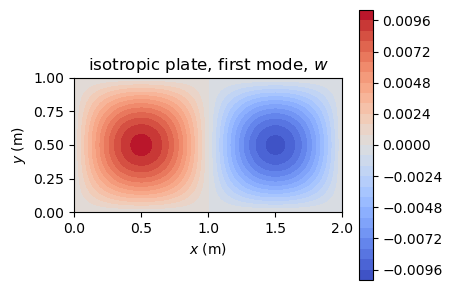

In [2]:
E, nu, h = 70e9, 0.33, 2e-3
s = Shell(model='plate_clpt_donnell', a=2., b=1., stack=[0.], plyt=h,
          laminaprop=(E, nu), m=12, n=12)
s.Nxx = -1.
eigvals, eigvecs = lb(s.calc_kC(), s.calc_kG(), silent=True)
D = E*h**3/(12*(1 - nu**2))
ms = np.arange(1, 6)
k = ((ms*s.b/s.a + s.a/(ms*s.b))**2).min()
Ncr = k*np.pi**2*D/s.b**2
print('panels: %.4f N/m, closed form: %.4f N/m (k = %.4f)'
      % (eigvals[0], Ncr, k))
iso_row = ('isotropic plate, $N_{xx,cr}$ (N/m)', eigvals[0], Ncr,
           'closed form, Timoshenko and Gere (1961)')
plot_modes([(s, eigvecs[:, 0])], ['isotropic plate, first mode, $w$'])

### Laminated plates, simply supported

For a symmetric laminate without bending-twisting coupling, $\boldsymbol{B} = \boldsymbol{0}$ and $D_{16} = D_{26} = 0$ (specially orthotropic), simply supported on all edges (SSSS), the modes are again $w = \sin(m\pi x/a)\sin(n\pi y/b)$, and Kassapoglou (2013), Eq. (6.4), p. 126, gives for the compressive loads $N_x$ and $N_y$, positive in compression, and the aspect ratio $AR = a/b$

$$
\pi^2 \left[D_{11} m^4 + 2(D_{12} + 2D_{66}) m^2 n^2 (AR)^2 + D_{22} n^4 (AR)^4\right] = a^2 \left[N_x m^2 + N_y n^2 (AR)^2\right],
$$

minimized over $m$ and $n$; with $N_y = k N_x$ it is Eq. (6.5), p. 127. In `panels` the compression is a negative `Nxx` or `Nyy`, so with `Nxx = -1` the load multiplier $\lambda$ is $N_x$ of this equation, and with `Nyy = -1` it is $N_y$ with $N_x = 0$. The stiffnesses $D_{ij}$, in N m, are those of the `ABD` matrix of the `Shell`.

The plate of $2 \times 1$ m first has the cross-ply laminate $[0/90/90/0]_s$ of carbon/epoxy plies of 0.125 mm, for which the equation is exact. Then the laminate $[0/90/-45/+45]_s$, with $D_{16}, D_{26} \neq 0$: for it Kassapoglou (2013, p. 128) uses the same equation, neglecting $D_{16}$ and $D_{26}$, as an approximation that gives "accurate trends and reasonable buckling predictions" when they are small compared with the other terms; the difference to `panels`, which keeps them, is the effect of the bending-twisting coupling. The cylindrical shell models with a large radius, $r = 10^8$ m, give the plate results.

In [3]:
LAMINA = (142.5e9, 8.7e9, 0.28, 5.1e9, 5.1e9, 5.1e9)
CROSS_PLY = [0, 90, 90, 0, 0, 90, 90, 0]
QUASI_ISO = [0, 90, -45, +45, +45, -45, 90, 0]


def ncr_orthotropic(D, a, b, load, nmax=10):
    """Kassapoglou (2013), Eq. (6.4): critical load of a specially
    orthotropic SSSS plate under Nx (load='Nxx') or Ny (load='Nyy')"""
    m, n = np.meshgrid(np.arange(1, nmax + 1), np.arange(1, nmax + 1))
    AR = a/b
    num = np.pi**2*(D[0, 0]*m**4 + 2*(D[0, 1] + 2*D[2, 2])*m**2*n**2*AR**2
                    + D[1, 1]*n**4*AR**4)
    den = a**2*(m**2 if load == 'Nxx' else n**2*AR**2)
    return (num/den).min()


def ssss(model, load, stack):
    s = Shell(model=model, a=2., b=1., r=1.e8, m=12, n=12, plyt=0.125e-3,
              stack=stack, laminaprop=LAMINA)
    setattr(s, load, -1.)
    return s


rows = []
modes = {}
for name, stack in (('$[0/90/90/0]_s$', CROSS_PLY),
                    ('$[0/90/-45/+45]_s$', QUASI_ISO)):
    for model in ['plate_clpt_donnell', 'cylshell_clpt_donnell',
                  'cylshell_clpt_sanders']:
        for load in ('Nxx', 'Nyy'):
            s = ssss(model, load, stack)
            eigvals, eigvecs = lb(s.calc_kC(), s.calc_kG(), silent=True)
            D = s.ABD[3:6, 3:6]
            ref = ncr_orthotropic(D, s.a, s.b, load)
            print('%-18s %-22s %s: lambda = %.6f N/m, Eq. (6.4): %.6f N/m'
                  % (name.strip('$'), model, load, eigvals[0], ref))
            src = ('Kassapoglou (2013), Eq. (6.4), p. 126' if stack is CROSS_PLY
                   else 'Kassapoglou (2013), Eq. (6.4) without $D_{16}$, $D_{26}$, p. 128')
            rows.append(('%s, `%s`, $%s$' % (name, model, load), eigvals[0],
                         ref, src))
            if model == 'plate_clpt_donnell':
                modes[(name, load)] = (s, eigvecs[:, 0])
    print('%s: D16/D11 = %.3f, D26/D22 = %.3f' % (name.strip('$'), D[0, 2]/D[0, 0],
                                                  D[1, 2]/D[1, 1]))
results_table(rows)

[0/90/90/0]_s      plate_clpt_donnell     Nxx: lambda = 145.759775 N/m, Eq. (6.4): 145.759775 N/m
[0/90/90/0]_s      plate_clpt_donnell     Nyy: lambda = 61.865033 N/m, Eq. (6.4): 61.865033 N/m
[0/90/90/0]_s      cylshell_clpt_donnell  Nxx: lambda = 145.759775 N/m, Eq. (6.4): 145.759775 N/m


[0/90/90/0]_s      cylshell_clpt_donnell  Nyy: lambda = 61.865033 N/m, Eq. (6.4): 61.865033 N/m
[0/90/90/0]_s      cylshell_clpt_sanders  Nxx: lambda = 145.759775 N/m, Eq. (6.4): 145.759775 N/m


[0/90/90/0]_s      cylshell_clpt_sanders  Nyy: lambda = 61.865033 N/m, Eq. (6.4): 61.865033 N/m
[0/90/90/0]_s: D16/D11 = 0.000, D26/D22 = 0.000
[0/90/-45/+45]_s   plate_clpt_donnell     Nxx: lambda = 157.538625 N/m, Eq. (6.4): 158.778583 N/m
[0/90/-45/+45]_s   plate_clpt_donnell     Nyy: lambda = 58.149231 N/m, Eq. (6.4): 58.429696 N/m


[0/90/-45/+45]_s   cylshell_clpt_donnell  Nxx: lambda = 157.538625 N/m, Eq. (6.4): 158.778583 N/m
[0/90/-45/+45]_s   cylshell_clpt_donnell  Nyy: lambda = 58.149231 N/m, Eq. (6.4): 58.429696 N/m


[0/90/-45/+45]_s   cylshell_clpt_sanders  Nxx: lambda = 157.538625 N/m, Eq. (6.4): 158.778583 N/m
[0/90/-45/+45]_s   cylshell_clpt_sanders  Nyy: lambda = 58.149231 N/m, Eq. (6.4): 58.429696 N/m
[0/90/-45/+45]_s: D16/D11 = -0.035, D26/D22 = -0.059


| quantity | panels | reference | relative difference | reference source |
|---|---|---|---|---|
| $[0/90/90/0]_s$, `plate_clpt_donnell`, $Nxx$ | 145.76 | 145.76 | +1.25e-11 | Kassapoglou (2013), Eq. (6.4), p. 126 |
| $[0/90/90/0]_s$, `plate_clpt_donnell`, $Nyy$ | 61.865 | 61.865 | +7.24e-15 | Kassapoglou (2013), Eq. (6.4), p. 126 |
| $[0/90/90/0]_s$, `cylshell_clpt_donnell`, $Nxx$ | 145.76 | 145.76 | +1.68e-11 | Kassapoglou (2013), Eq. (6.4), p. 126 |
| $[0/90/90/0]_s$, `cylshell_clpt_donnell`, $Nyy$ | 61.865 | 61.865 | +1.01e-11 | Kassapoglou (2013), Eq. (6.4), p. 126 |
| $[0/90/90/0]_s$, `cylshell_clpt_sanders`, $Nxx$ | 145.76 | 145.76 | +1.68e-11 | Kassapoglou (2013), Eq. (6.4), p. 126 |
| $[0/90/90/0]_s$, `cylshell_clpt_sanders`, $Nyy$ | 61.865 | 61.865 | +1.01e-11 | Kassapoglou (2013), Eq. (6.4), p. 126 |
| $[0/90/-45/+45]_s$, `plate_clpt_donnell`, $Nxx$ | 157.539 | 158.779 | -7.81e-03 | Kassapoglou (2013), Eq. (6.4) without $D_{16}$, $D_{26}$, p. 128 |
| $[0/90/-45/+45]_s$, `plate_clpt_donnell`, $Nyy$ | 58.1492 | 58.4297 | -4.80e-03 | Kassapoglou (2013), Eq. (6.4) without $D_{16}$, $D_{26}$, p. 128 |
| $[0/90/-45/+45]_s$, `cylshell_clpt_donnell`, $Nxx$ | 157.539 | 158.779 | -7.81e-03 | Kassapoglou (2013), Eq. (6.4) without $D_{16}$, $D_{26}$, p. 128 |
| $[0/90/-45/+45]_s$, `cylshell_clpt_donnell`, $Nyy$ | 58.1492 | 58.4297 | -4.80e-03 | Kassapoglou (2013), Eq. (6.4) without $D_{16}$, $D_{26}$, p. 128 |
| $[0/90/-45/+45]_s$, `cylshell_clpt_sanders`, $Nxx$ | 157.539 | 158.779 | -7.81e-03 | Kassapoglou (2013), Eq. (6.4) without $D_{16}$, $D_{26}$, p. 128 |
| $[0/90/-45/+45]_s$, `cylshell_clpt_sanders`, $Nyy$ | 58.1492 | 58.4297 | -4.80e-03 | Kassapoglou (2013), Eq. (6.4) without $D_{16}$, $D_{26}$, p. 128 |

The cross-ply plate agrees with the exact solution to the digits printed. The quasi-isotropic plate, with $|D_{16}/D_{11}| = 0.035$ and $|D_{26}/D_{22}| = 0.059$, buckles at a load 0.8% ($N_{xx}$) and 0.5% ($N_{yy}$) lower than the approximation without $D_{16}$ and $D_{26}$: the bending-twisting coupling skews the half-waves, as the mode plots below show, and lowers the critical load, so the approximation is slightly unconservative here.

### Plate with one free edge

The plate of $1 \times 0.5$ m with the cross-ply laminate $[0/90/90/0]_s$ has one free edge: $u$, $v$ and $w$ are released at $y = b$ (`y2u`, `y2v`, `y2w`) for $N_{xx}$, and at $x = a$ for $N_{yy}$; the other three edges are simply supported. The laminate is specially orthotropic, and the problem has an exact solution (Leissa, 1985, Chapter III). With $w = Y(\eta)\sin(m\pi x/a)$ and $\eta = y/b$ (Eq. (3.2)), the equilibrium equation of the orthotropic plate under a uniform $N_x$ becomes (Eqs. (3.3), (3.4))

$$
Y^{\mathrm{IV}} - A Y^{\mathrm{II}} - B Y = 0, \qquad A = 2 C_2 \pi^2 \rho^2, \qquad B = \pi^2 \rho^2 \left(K_x - C_1 \pi^2 \rho^2\right),
$$

with $\rho = m b/a$, the load parameter $K_x = N_x b^2/D_{22}$, positive in compression (Eq. (2.11)), $C_1 = D_{11}/D_{22}$ and $C_2 = (D_{12} + 2D_{66})/D_{22}$ (Eq. (2.16)). For $B > 0$, that is $N_x > D_{11} (m\pi/a)^2$, the roots of the auxiliary equation (Eqs. (3.6), (3.7)) are $\alpha^2 > 0$ and $-\beta^2 < 0$, $\alpha^2, -\beta^2 = (A \pm \sqrt{A^2 + 4B})/2$, and the solution that satisfies $w = M_y = 0$ at the simply supported edge $y = 0$ is $Y = a_1 \sin\beta\eta + a_3 \sinh\alpha\eta$ (Eq. (3.11)). At the free edge $y = b$, $M_y = V_y = 0$ (Eq. (3.41b)), with $M_y = -(D_{12} w_{,xx} + D_{22} w_{,yy})$ and $V_y = -(D_{12} + 4D_{66}) w_{,xxy} - D_{22} w_{,yyy}$ (Eqs. (A.38e) and (A.38j) with $\boldsymbol{B} = \boldsymbol{0}$ and $D_{16} = D_{26} = 0$). Nontrivial $a_1$, $a_3$ require

$$
\alpha \left(\beta^2 + c\pi^2\rho^2\right)\left(\alpha^2 - d\pi^2\rho^2\right) \sin\beta \cosh\alpha = \beta \left(\alpha^2 - c\pi^2\rho^2\right)\left(\beta^2 + d\pi^2\rho^2\right) \sinh\alpha \cos\beta,
$$

with $c = D_{12}/D_{22}$ and $d = (D_{12} + 4D_{66})/D_{22}$; for an isotropic plate, $c = \nu$ and $d = 2 - \nu$, it is the characteristic equation (3.42) of Leissa (1985). The critical load is the smallest root $N_x$ over the half-waves $m$, found by `ncr_sssf` with a scan of the sign of the determinant and `scipy.optimize.brentq`. The load $N_{yy}$ with the free edge $x = a$ is the same problem with $x$ and $y$, $a$ and $b$, and $D_{11}$ and $D_{22}$ exchanged.

For a long plate, $a/b > 4$, Barbero (2017), Eq. (11.16), p. 406, gives the approximation

$$
N_{x,cr} = \frac{12 D_{66}}{b^2} + \frac{\pi^2 D_{11}}{a^2},
$$

compared below for a plate of $2.5 \times 0.5$ m with the same laminate.

In [4]:
from scipy.optimize import brentq


def sssf_det(N, D, a, b, m):
    """Determinant of the SSSF orthotropic plate, free edge y = b, under the
    compression N (positive), scaled by 1/cosh(alpha); Leissa (1985),
    Eqs. (3.2)-(3.11), (3.41), (A.38e), (A.38j)"""
    D11, D12, D22, D66 = D[0, 0], D[0, 1], D[1, 1], D[2, 2]
    rho2 = (m*np.pi*b/a)**2  # pi^2 rho^2
    Kx = N*b**2/D22
    A = 2*(D12 + 2*D66)/D22*rho2
    B = rho2*(Kx - D11/D22*rho2)
    root = np.sqrt(A**2 + 4*B)
    alpha, beta = np.sqrt((A + root)/2), np.sqrt(-(A - root)/2)
    c, d = D12/D22, (D12 + 4*D66)/D22
    return (alpha*(beta**2 + c*rho2)*(alpha**2 - d*rho2)*np.sin(beta)
            - beta*(alpha**2 - c*rho2)*(beta**2 + d*rho2)*np.tanh(alpha)
            * np.cos(beta))


def ncr_sssf(D, a, b, mmax=6):
    """Smallest critical compression N_x of the SSSF orthotropic plate and
    its number of half-waves m along x"""
    out = []
    for m in range(1, mmax + 1):
        N = D[0, 0]*(m*np.pi/a)**2*np.logspace(1e-6, 3, 4000)  # B > 0
        f = np.array([sssf_det(Ni, D, a, b, m) for Ni in N])
        i = np.nonzero(np.sign(f[:-1]) != np.sign(f[1:]))[0][0]
        out.append((brentq(sssf_det, N[i], N[i + 1], args=(D, a, b, m),
                           xtol=1e-14, rtol=1e-14), m))
    return min(out)


def swap_xy(D):
    """Bending stiffnesses with the axes x and y exchanged"""
    return D[[1, 0, 2]][:, [1, 0, 2]]


def one_free_edge(model, load, a=1., b=0.5):
    s = Shell(model=model, a=a, b=b, r=1.e8, m=12, n=13, plyt=0.125e-3,
              stack=CROSS_PLY, laminaprop=LAMINA)
    edge = 'y2' if load == 'Nxx' else 'x2'
    for field in 'uvw':
        setattr(s, edge + field, 1)
    setattr(s, load, -1.)
    return s


rows = []
for model in ['plate_clpt_donnell', 'cylshell_clpt_donnell',
              'cylshell_clpt_sanders']:
    for load in ('Nxx', 'Nyy'):
        s = one_free_edge(model, load)
        eigvals, eigvecs = lb(s.calc_kC(), s.calc_kG(), silent=True)
        D = s.ABD[3:6, 3:6]
        if load == 'Nxx':
            ref, m = ncr_sssf(D, s.a, s.b)
        else:
            ref, m = ncr_sssf(swap_xy(D), s.b, s.a)
        print('%-22s free edge %s: lambda = %.6f N/m, exact: %.6f N/m (m = %d)'
              % (model, load, eigvals[0], ref, m))
        rows.append(('`%s`, free edge, $%s$' % (model, load), eigvals[0], ref,
                     'exact, Leissa (1985), Eqs. (3.2)-(3.11), (3.41)'))
        if model == 'plate_clpt_donnell':
            modes[('free edge', load)] = (s, eigvecs[:, 0])

s = one_free_edge('plate_clpt_donnell', 'Nxx', a=2.5, b=0.5)
eigvals, eigvecs = lb(s.calc_kC(), s.calc_kG(), silent=True)
D = s.ABD[3:6, 3:6]
exact, m = ncr_sssf(D, s.a, s.b)
barbero = 12*D[2, 2]/s.b**2 + np.pi**2*D[0, 0]/s.a**2
print('long plate a/b = %g: lambda = %.6f N/m, exact: %.6f N/m (m = %d), '
      'Eq. (11.16): %.6f N/m' % (s.a/s.b, eigvals[0], exact, m, barbero))
rows.append(('`plate_clpt_donnell`, free edge, $a/b = 5$, $N_{xx}$',
             eigvals[0], exact, 'exact, Leissa (1985), Eqs. (3.2)-(3.11), (3.41)'))
rows.append(('`plate_clpt_donnell`, free edge, $a/b = 5$, $N_{xx}$',
             eigvals[0], barbero, 'Barbero (2017), Eq. (11.16), p. 406'))
results_table(rows)

plate_clpt_donnell     free edge Nxx: lambda = 93.126602 N/m, exact: 93.126602 N/m (m = 1)


plate_clpt_donnell     free edge Nyy: lambda = 213.351178 N/m, exact: 213.351178 N/m (m = 1)


cylshell_clpt_donnell  free edge Nxx: lambda = 93.126602 N/m, exact: 93.126602 N/m (m = 1)


cylshell_clpt_donnell  free edge Nyy: lambda = 213.351178 N/m, exact: 213.351178 N/m (m = 1)


cylshell_clpt_sanders  free edge Nxx: lambda = 93.126602 N/m, exact: 93.126602 N/m (m = 1)


cylshell_clpt_sanders  free edge Nyy: lambda = 213.351178 N/m, exact: 213.351178 N/m (m = 1)


long plate a/b = 5: lambda = 32.034959 N/m, exact: 32.034959 N/m (m = 1), Eq. (11.16): 32.055040 N/m


| quantity | panels | reference | relative difference | reference source |
|---|---|---|---|---|
| `plate_clpt_donnell`, free edge, $Nxx$ | 93.1266 | 93.1266 | -5.65e-15 | exact, Leissa (1985), Eqs. (3.2)-(3.11), (3.41) |
| `plate_clpt_donnell`, free edge, $Nyy$ | 213.351 | 213.351 | -4.00e-15 | exact, Leissa (1985), Eqs. (3.2)-(3.11), (3.41) |
| `cylshell_clpt_donnell`, free edge, $Nxx$ | 93.1266 | 93.1266 | +1.48e-13 | exact, Leissa (1985), Eqs. (3.2)-(3.11), (3.41) |
| `cylshell_clpt_donnell`, free edge, $Nyy$ | 213.351 | 213.351 | +7.34e-13 | exact, Leissa (1985), Eqs. (3.2)-(3.11), (3.41) |
| `cylshell_clpt_sanders`, free edge, $Nxx$ | 93.1266 | 93.1266 | +1.45e-13 | exact, Leissa (1985), Eqs. (3.2)-(3.11), (3.41) |
| `cylshell_clpt_sanders`, free edge, $Nyy$ | 213.351 | 213.351 | +7.25e-13 | exact, Leissa (1985), Eqs. (3.2)-(3.11), (3.41) |
| `plate_clpt_donnell`, free edge, $a/b = 5$, $N_{xx}$ | 32.035 | 32.035 | +2.66e-14 | exact, Leissa (1985), Eqs. (3.2)-(3.11), (3.41) |
| `plate_clpt_donnell`, free edge, $a/b = 5$, $N_{xx}$ | 32.035 | 32.055 | -6.26e-04 | Barbero (2017), Eq. (11.16), p. 406 |

The first buckling modes of the plate model: the SSSS plates under $N_{xx}$, cross-ply and quasi-isotropic, and the plate with the free edge, which buckles with the largest deflection along the free edge.

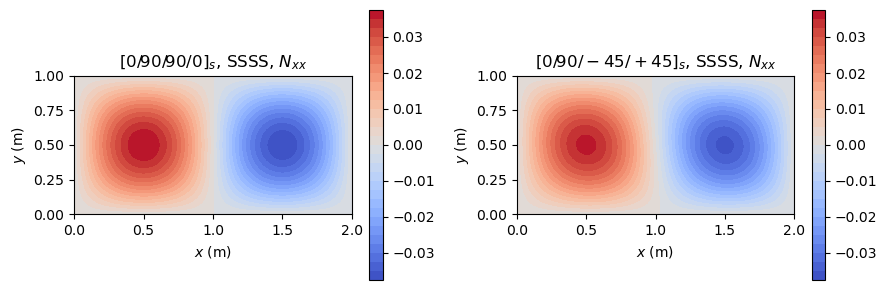

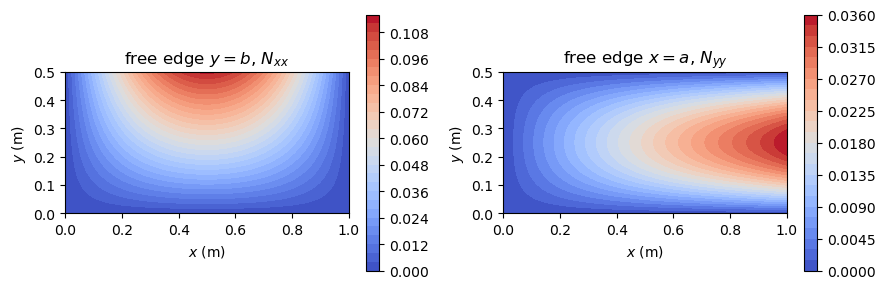

In [5]:
plot_modes([modes[('$[0/90/90/0]_s$', 'Nxx')], modes[('$[0/90/-45/+45]_s$', 'Nxx')]],
           ['$[0/90/90/0]_s$, SSSS, $N_{xx}$', '$[0/90/-45/+45]_s$, SSSS, $N_{xx}$'])
plot_modes([modes[('free edge', 'Nxx')], modes[('free edge', 'Nyy')]],
           ['free edge $y = b$, $N_{xx}$', 'free edge $x = a$, $N_{yy}$'])

### Combined loads

Combined load cases are given by more than one stress resultant; the load multiplier scales all of them. Leissa (1985), Table 2.9, p. 42, lists the buckling loads computed by Chamis for simply supported (SSSS) plates under combinations of compression $N_x$ and shear $N_{xy}$, with the Galerkin method and 5 by 5 sine terms (Leissa, 1985, p. 40). The isotropic aluminium plates of that table, with $E = 10 \times 10^6$ psi, $\nu = 0.30$ (Table 2.7, p. 41) and the bending stiffness $D = 810.1$ lb in (Table 2.8, p. 41), which gives the thickness $h$, have a width $b = 10$ in and a length $a = 5$, 10 and 20 in (the side of 10 in is loaded by $N_x$: the pure compression values are those of the closed form of the isotropic plate above). The loads of the table are $N_x/N_{cr}$ and $N_{xy}/N_{cr}$ in lb/in, so with `Nxx` and `Nxy` set to these ratios $\lambda = N_{cr}$; "pure" shear has $N_x/N_{cr} = -0.001$ in the table, kept here. In-plane boundary conditions do not change $\lambda$ of a flat isotropic plate.

In [6]:
E_AL, NU_AL, D_AL = 10.e6, 0.30, 810.1  # psi, -, lb in; Leissa (1985), Tables 2.7, 2.8
H_AL = (12*(1 - NU_AL**2)*D_AL/E_AL)**(1/3)
print('thickness h = %.5f in' % H_AL)
CHAMIS = [  # (a, b) in, (Nx/Ncr, Nxy/Ncr), Ncr in lb/in; Leissa (1985), Table 2.9
    ((5., 10.), (-1, 0), 500), ((5., 10.), (-1, 1), 479),
    ((5., 10.), (-0.001, 1), 2104),
    ((10., 10.), (-1, 0), 320), ((10., 10.), (-1, 1), 277),
    ((10., 10.), (-0.001, 1), 752),
    ((20., 10.), (-1, 0), 320), ((20., 10.), (-1, 1), 250),
    ((20., 10.), (-0.001, 1), 528)]
rows = []
for model in ('plate_clpt_donnell', 'cylshell_clpt_donnell'):
    for (a, b), (nx, nxy), ref in CHAMIS:
        s = Shell(model=model, a=a, b=b, r=1.e8, m=12, n=12, stack=[0.],
                  plyt=H_AL, laminaprop=(E_AL, NU_AL))
        s.Nxx, s.Nxy = nx, nxy
        eigvals, eigvecs = lb(s.calc_kC(), s.calc_kG(), silent=True)
        print('%-22s %g x %g in, Nx = %g, Nxy = %g: lambda = %.2f lb/in, '
              'Table 2.9: %g lb/in' % (model, a, b, nx, nxy, eigvals[0], ref))
        rows.append(('`%s`, $%g \\times %g$ in, $N_x = %g$, $N_{xy} = %g$'
                     % (model, a, b, nx, nxy), eigvals[0], ref,
                     'Chamis, Leissa (1985), Table 2.9, p. 42'))
results_table(rows)

thickness h = 0.09600 in
plate_clpt_donnell     5 x 10 in, Nx = -1, Nxy = 0: lambda = 499.71 lb/in, Table 2.9: 500 lb/in
plate_clpt_donnell     5 x 10 in, Nx = -1, Nxy = 1: lambda = 478.21 lb/in, Table 2.9: 479 lb/in


plate_clpt_donnell     5 x 10 in, Nx = -0.001, Nxy = 1: lambda = 2089.98 lb/in, Table 2.9: 2104 lb/in
plate_clpt_donnell     10 x 10 in, Nx = -1, Nxy = 0: lambda = 319.81 lb/in, Table 2.9: 320 lb/in
plate_clpt_donnell     10 x 10 in, Nx = -1, Nxy = 1: lambda = 276.15 lb/in, Table 2.9: 277 lb/in


plate_clpt_donnell     10 x 10 in, Nx = -0.001, Nxy = 1: lambda = 744.65 lb/in, Table 2.9: 752 lb/in
plate_clpt_donnell     20 x 10 in, Nx = -1, Nxy = 0: lambda = 319.81 lb/in, Table 2.9: 320 lb/in
plate_clpt_donnell     20 x 10 in, Nx = -1, Nxy = 1: lambda = 248.16 lb/in, Table 2.9: 250 lb/in


plate_clpt_donnell     20 x 10 in, Nx = -0.001, Nxy = 1: lambda = 523.04 lb/in, Table 2.9: 528 lb/in
cylshell_clpt_donnell  5 x 10 in, Nx = -1, Nxy = 0: lambda = 499.71 lb/in, Table 2.9: 500 lb/in


cylshell_clpt_donnell  5 x 10 in, Nx = -1, Nxy = 1: lambda = 478.21 lb/in, Table 2.9: 479 lb/in
cylshell_clpt_donnell  5 x 10 in, Nx = -0.001, Nxy = 1: lambda = 2089.98 lb/in, Table 2.9: 2104 lb/in


cylshell_clpt_donnell  10 x 10 in, Nx = -1, Nxy = 0: lambda = 319.81 lb/in, Table 2.9: 320 lb/in
cylshell_clpt_donnell  10 x 10 in, Nx = -1, Nxy = 1: lambda = 276.15 lb/in, Table 2.9: 277 lb/in


cylshell_clpt_donnell  10 x 10 in, Nx = -0.001, Nxy = 1: lambda = 744.65 lb/in, Table 2.9: 752 lb/in
cylshell_clpt_donnell  20 x 10 in, Nx = -1, Nxy = 0: lambda = 319.81 lb/in, Table 2.9: 320 lb/in


cylshell_clpt_donnell  20 x 10 in, Nx = -1, Nxy = 1: lambda = 248.16 lb/in, Table 2.9: 250 lb/in
cylshell_clpt_donnell  20 x 10 in, Nx = -0.001, Nxy = 1: lambda = 523.04 lb/in, Table 2.9: 528 lb/in


| quantity | panels | reference | relative difference | reference source |
|---|---|---|---|---|
| `plate_clpt_donnell`, $5 \times 10$ in, $N_x = -1$, $N_{xy} = 0$ | 499.71 | 500 | -5.79e-04 | Chamis, Leissa (1985), Table 2.9, p. 42 |
| `plate_clpt_donnell`, $5 \times 10$ in, $N_x = -1$, $N_{xy} = 1$ | 478.212 | 479 | -1.64e-03 | Chamis, Leissa (1985), Table 2.9, p. 42 |
| `plate_clpt_donnell`, $5 \times 10$ in, $N_x = -0.001$, $N_{xy} = 1$ | 2089.98 | 2104 | -6.66e-03 | Chamis, Leissa (1985), Table 2.9, p. 42 |
| `plate_clpt_donnell`, $10 \times 10$ in, $N_x = -1$, $N_{xy} = 0$ | 319.815 | 320 | -5.79e-04 | Chamis, Leissa (1985), Table 2.9, p. 42 |
| `plate_clpt_donnell`, $10 \times 10$ in, $N_x = -1$, $N_{xy} = 1$ | 276.151 | 277 | -3.07e-03 | Chamis, Leissa (1985), Table 2.9, p. 42 |
| `plate_clpt_donnell`, $10 \times 10$ in, $N_x = -0.001$, $N_{xy} = 1$ | 744.645 | 752 | -9.78e-03 | Chamis, Leissa (1985), Table 2.9, p. 42 |
| `plate_clpt_donnell`, $20 \times 10$ in, $N_x = -1$, $N_{xy} = 0$ | 319.815 | 320 | -5.79e-04 | Chamis, Leissa (1985), Table 2.9, p. 42 |
| `plate_clpt_donnell`, $20 \times 10$ in, $N_x = -1$, $N_{xy} = 1$ | 248.161 | 250 | -7.36e-03 | Chamis, Leissa (1985), Table 2.9, p. 42 |
| `plate_clpt_donnell`, $20 \times 10$ in, $N_x = -0.001$, $N_{xy} = 1$ | 523.036 | 528 | -9.40e-03 | Chamis, Leissa (1985), Table 2.9, p. 42 |
| `cylshell_clpt_donnell`, $5 \times 10$ in, $N_x = -1$, $N_{xy} = 0$ | 499.71 | 500 | -5.79e-04 | Chamis, Leissa (1985), Table 2.9, p. 42 |
| `cylshell_clpt_donnell`, $5 \times 10$ in, $N_x = -1$, $N_{xy} = 1$ | 478.212 | 479 | -1.64e-03 | Chamis, Leissa (1985), Table 2.9, p. 42 |
| `cylshell_clpt_donnell`, $5 \times 10$ in, $N_x = -0.001$, $N_{xy} = 1$ | 2089.98 | 2104 | -6.66e-03 | Chamis, Leissa (1985), Table 2.9, p. 42 |
| `cylshell_clpt_donnell`, $10 \times 10$ in, $N_x = -1$, $N_{xy} = 0$ | 319.815 | 320 | -5.79e-04 | Chamis, Leissa (1985), Table 2.9, p. 42 |
| `cylshell_clpt_donnell`, $10 \times 10$ in, $N_x = -1$, $N_{xy} = 1$ | 276.151 | 277 | -3.07e-03 | Chamis, Leissa (1985), Table 2.9, p. 42 |
| `cylshell_clpt_donnell`, $10 \times 10$ in, $N_x = -0.001$, $N_{xy} = 1$ | 744.645 | 752 | -9.78e-03 | Chamis, Leissa (1985), Table 2.9, p. 42 |
| `cylshell_clpt_donnell`, $20 \times 10$ in, $N_x = -1$, $N_{xy} = 0$ | 319.815 | 320 | -5.79e-04 | Chamis, Leissa (1985), Table 2.9, p. 42 |
| `cylshell_clpt_donnell`, $20 \times 10$ in, $N_x = -1$, $N_{xy} = 1$ | 248.161 | 250 | -7.36e-03 | Chamis, Leissa (1985), Table 2.9, p. 42 |
| `cylshell_clpt_donnell`, $20 \times 10$ in, $N_x = -0.001$, $N_{xy} = 1$ | 523.036 | 528 | -9.40e-03 | Chamis, Leissa (1985), Table 2.9, p. 42 |

The values of `panels` lie up to 1% below those of the table, most for the shear loads: the Galerkin solution with 5 by 5 terms is not converged in shear, while `panels` with $12 \times 12$ terms is; for pure compression, the exact value of the closed form, the table is within 0.06%.

The same loads act on a curved panel: an isotropic aluminium cylindrical panel of $2 \times 1$ m, radius $r = 2$ m and thickness 1 mm, with Donnell's kinematics, simply supported, under $N_{xx} = N_{xy} = -1$ N/m. Leissa (1985), Figs. 10.10 to 10.19, shows combined loads on curved panels only as curves for infinitely long or clamped panels, so no published value is compared for this panel.

curved panel, first load multipliers: [4651.652 4699.137 5531.811 5587.955]


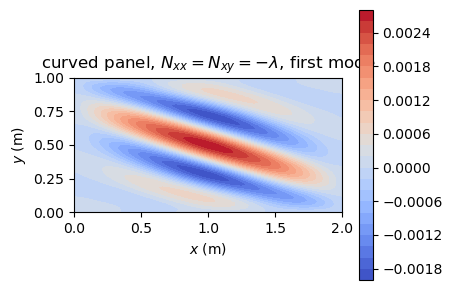

In [7]:
s = Shell(model='cylshell_clpt_donnell', a=2., b=1., r=2., m=12, n=12,
          stack=[0.], plyt=1e-3, laminaprop=(70e9, 0.33))
s.Nxx = -1.
s.Nxy = -1.
eigvals, eigvecs = lb(s.calc_kC(), s.calc_kG(), silent=True)
print('curved panel, first load multipliers:', np.round(eigvals[:4], 3))
plot_modes([(s, eigvecs[:, 0])], ['curved panel, $N_{xx} = N_{xy} = -\\lambda$, first mode'])

## Pre-buckling stress state from a static analysis

$\boldsymbol{K}_G$ can also be computed from the Ritz constants $\boldsymbol{c}_0$ of a linear static solution, `Shell.calc_kG(c=c0)`, which integrates the pre-buckling stress field numerically. The stresses then follow the boundary conditions instead of being assumed constant.

The plate of $8 \times 4$ m with the cross-ply laminate $[0/90/90/0]$ is compressed by a load of 1 N/m distributed along $x = a$. The in-plane boundary conditions let the edges move: $u$ is free except at $x = 0$, and $v$ is constrained only along $x = 0$. The critical $N_{xx}$ is computed first with a constant $N_{xx} = -1$ and then with the pre-buckling state of the static solution under the same load. The laminate is specially orthotropic and $w$ is simply supported at all edges, so both are compared with Kassapoglou (2013), Eq. (6.4). The static state is not exactly uniform: $v = 0$ along $x = 0$ restrains the Poisson expansion there, and the critical load from it is 0.03% lower.

In [8]:
def plate_8x4(model, stack=(0, 90, 90, 0)):
    p = Shell(model=model, a=8., b=4., r=1.e8, m=8, n=9, plyt=0.125e-3,
              stack=list(stack), laminaprop=LAMINA)
    p.x1ur = 1
    p.x2u = p.x2ur = 1
    p.y1u = p.y1ur = p.y2u = p.y2ur = 1
    p.x1v = p.x1vr = 0
    p.x2v = p.x2vr = p.y1v = p.y1vr = p.y2v = p.y2vr = 1
    return p


def lb_constant_and_static(p):
    p.Nxx = -1.
    k0 = p.calc_kC(silent=True)
    eig_cte, _ = lb(k0, p.calc_kG(silent=True), silent=True)
    p.Nxx = 0.
    p.add_distr_load_fixed_x(p.a, lambda y: -1., None, None)
    c0 = solve(k0, p.calc_fext(silent=True), silent=True)
    eig_static, modes = lb(k0, p.calc_kG(c=c0, silent=True), silent=True)
    return eig_cte[0], eig_static[0], c0, modes


import warnings
warnings.showwarning = lambda message, category, *args, **kwargs: print(
    '%s: %s' % (category.__name__, message))
rows = []
for model in ['plate_clpt_donnell', 'cylshell_clpt_donnell',
              'cylshell_clpt_sanders', 'plate_fsdt_donnell',
              'plate_tsdt_donnell']:
    p = plate_8x4(model)
    lbd_cte, lbd_static, c0, modes = lb_constant_and_static(p)
    ref = ncr_orthotropic(p.ABD[3:6, 3:6], p.a, p.b, 'Nxx')
    print('%-22s constant Nxx: %.5f, from the static solution: %.5f, '
          'Eq. (6.4): %.5f N/m' % (model, lbd_cte, lbd_static, ref))
    rows.append(('`%s`, constant $N_{xx}$' % model, lbd_cte, ref,
                 'Kassapoglou (2013), Eq. (6.4), p. 126'))
    rows.append(('`%s`, $N_{xx}$ from static' % model, lbd_static, ref,
                 'Kassapoglou (2013), Eq. (6.4), p. 126'))
results_table(rows)

plate_clpt_donnell     constant Nxx: 1.02217, from the static solution: 1.02184, Eq. (6.4): 1.02217 N/m
cylshell_clpt_donnell  constant Nxx: 1.02217, from the static solution: 1.02184, Eq. (6.4): 1.02217 N/m
cylshell_clpt_sanders  constant Nxx: 1.02217, from the static solution: 1.02184, Eq. (6.4): 1.02217 N/m


plate_fsdt_donnell     constant Nxx: 1.02217, from the static solution: 1.02184, Eq. (6.4): 1.02217 N/m


plate_tsdt_donnell     constant Nxx: 1.02217, from the static solution: 1.02184, Eq. (6.4): 1.02217 N/m


| quantity | panels | reference | relative difference | reference source |
|---|---|---|---|---|
| `plate_clpt_donnell`, constant $N_{xx}$ | 1.02217 | 1.02217 | +4.70e-08 | Kassapoglou (2013), Eq. (6.4), p. 126 |
| `plate_clpt_donnell`, $N_{xx}$ from static | 1.02184 | 1.02217 | -3.27e-04 | Kassapoglou (2013), Eq. (6.4), p. 126 |
| `cylshell_clpt_donnell`, constant $N_{xx}$ | 1.02217 | 1.02217 | +4.72e-08 | Kassapoglou (2013), Eq. (6.4), p. 126 |
| `cylshell_clpt_donnell`, $N_{xx}$ from static | 1.02184 | 1.02217 | -3.27e-04 | Kassapoglou (2013), Eq. (6.4), p. 126 |
| `cylshell_clpt_sanders`, constant $N_{xx}$ | 1.02217 | 1.02217 | +4.72e-08 | Kassapoglou (2013), Eq. (6.4), p. 126 |
| `cylshell_clpt_sanders`, $N_{xx}$ from static | 1.02184 | 1.02217 | -3.27e-04 | Kassapoglou (2013), Eq. (6.4), p. 126 |
| `plate_fsdt_donnell`, constant $N_{xx}$ | 1.02217 | 1.02217 | -8.42e-08 | Kassapoglou (2013), Eq. (6.4), p. 126 |
| `plate_fsdt_donnell`, $N_{xx}$ from static | 1.02184 | 1.02217 | -3.27e-04 | Kassapoglou (2013), Eq. (6.4), p. 126 |
| `plate_tsdt_donnell`, constant $N_{xx}$ | 1.02217 | 1.02217 | -6.40e-08 | Kassapoglou (2013), Eq. (6.4), p. 126 |
| `plate_tsdt_donnell`, $N_{xx}$ from static | 1.02184 | 1.02217 | -3.27e-04 | Kassapoglou (2013), Eq. (6.4), p. 126 |

For some models, `structsolve.lb` may warn that its sparse eigensolvers did not reach the required accuracy, and then solves the problem with its dense solver instead; the results are not affected.

With an unsymmetric laminate, $\boldsymbol{B} \neq \boldsymbol{0}$, the in-plane load of the static solution also bends the plate and changes the pre-buckling stresses, and the two pre-buckling states give different critical loads; no closed form exists then. For the laminate $[0/90/90/0/-45/+45]$:

In [9]:
lbd_cte, lbd_static, _, _ = lb_constant_and_static(
    plate_8x4('plate_clpt_donnell', stack=(0, 90, 90, 0, -45, +45)))
print('constant Nxx: %.5f N/m, from the static solution: %.5f N/m (%+.2f%%)'
      % (lbd_cte, lbd_static, 100*(lbd_static/lbd_cte - 1)))

constant Nxx: 4.47698 N/m, from the static solution: 4.39212 N/m (-1.90%)


The pre-buckling stress resultant $N_{xx}$ of the static solution, and the first buckling mode computed with it, for the last model of the cross-ply loop:

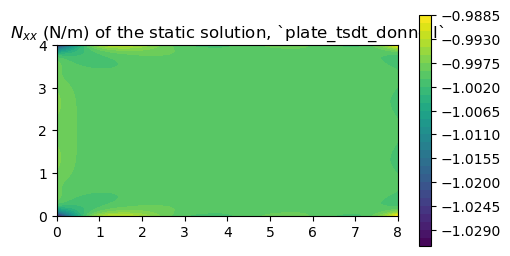

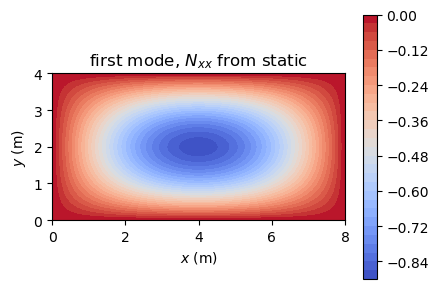

In [10]:
mesh, fields = p.stress(c0, gridx=101, gridy=61)
fig, ax = plt.subplots(figsize=(5.5, 3))
cf = ax.contourf(mesh['Xs'], mesh['Ys'], fields['Nxx'], levels=30,
                 cmap='viridis')
fig.colorbar(cf, ax=ax)
ax.set_title('$N_{xx}$ (N/m) of the static solution, `%s`' % p.model)
ax.set_aspect('equal')
plt.show()
plot_modes([(p, modes[:, 0])], ['first mode, $N_{xx}$ from static'])

## Discussion

The isotropic plate and the specially orthotropic cross-ply plates agree with the closed forms, with a constant pre-buckling state and with the state of the static solution, for the plate models and for the cylindrical shell models with a large radius. The pre-buckling state of the static solution lowers the critical load by 1.9% for the unsymmetric laminate. The bending-twisting coupling of the quasi-isotropic laminate lowers its critical load below the approximation of Kassapoglou (2013) that neglects $D_{16}$ and $D_{26}$. The plate with one free edge agrees with the exact solution of Leissa (1985) to the digits of the solution, and the long plate is 0.06% below the approximation of Barbero (2017). The flat plates under compression and shear agree with the Galerkin solutions listed by Leissa (1985) within 1%; the curved panel under the same loads has no tabulated reference.

## References

1. S. P. Timoshenko and J. M. Gere, "Theory of Elastic Stability". 2nd ed., McGraw-Hill, New York, 1961.
2. C. Kassapoglou, "Design and Analysis of Composite Structures: With Applications to Aerospace Structures". 2nd ed., Wiley, Chichester, 2013. https://doi.org/10.1002/9781118536933.
3. A. W. Leissa, "Buckling of Laminated Composite Plates and Shell Panels". Report AFWAL-TR-85-3069, Air Force Wright Aeronautical Laboratories, Wright-Patterson Air Force Base, Ohio, 1985.
4. E. J. Barbero, "Introduction to Composite Materials Design". 3rd ed., CRC Press, Boca Raton, 2017. https://doi.org/10.1201/9781315296494.
5. S. G. P. Castro and M. V. Donadon, "Assembly of semi-analytical models to address linear buckling and vibration of stiffened composite panels with debonding defect". Composite Structures, 160:232-247, 2017. https://doi.org/10.1016/j.compstruct.2016.10.026.